# 2. A retailer that finances its stock from cash: writing your own simulator

A retailer sells three lines over a year of 52 weeks: a staple with a thin margin and steady demand, a seasonal line
with a high margin whose demand peaks before the year end, and a fashion line with a high margin and volatile demand.
It pays suppliers when it orders, and the seasonal goods take eight weeks to arrive, so the seasonal stock has to be
bought before the season shows how strong it is. A fixed overhead is due every week. The firm starts the year with
2,500 in cash (hundreds of dollars) and has no credit line: the first week that ends with negative cash is
insolvency. Buying more seasonal stock earns more on average and makes insolvency more likely in a weak year.

No Gymnasium task exists for this problem, so we write the simulator ourselves. The notebook goes through the steps
of the [practitioner guide](../docs/practitioner-guide.md) with all the code in view:

1. write the simulator: a class with `reset` and `step`;
2. define the problem as a budget: a resource that is also replenished (cash), a known cost of failure;
3. check the wrapped simulator and plan;
4. evaluate the rule already in use, which is a candidate too;
5. train PPO, and read the learning curves;
6. compare the costs of failure in the full campaign, and the dispersion of the deployed policy;
7. start a learner from the rule: fit a prior, anchor to it;
8. aim at a tolerance with an adaptive multiplier;
9. validate the candidates and report.

Notes marked **Theory** say what the results behind the method imply at each step. The training here is short; the
comparisons use the full campaign in `campaigns/` (10 million steps per run, three seeds), which ran this same code.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
from stable_baselines3 import PPO
from stable_baselines3.common.vec_env import DummyVecEnv, VecNormalize

from barrierpg import BudgetSpec, Requirement, Stage, BudgetWrapper, RunningMaxCost, evaluate, interpret, plan
from barrierpg.callbacks import BudgetMonitor, DualAscent, ParameterAnchor, fit_actor_mean, set_log_std
from barrierpg.problems.inventory import Retailer, InventoryCore, BaseStockRule

sys.path.insert(0, str(Path("..").resolve() / "campaigns"))
from records import Campaign                     # the records of the full campaign
camp = Campaign("retailer")
torch.set_num_threads(1)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

## 1. Write the simulator

A simulator needs `reset(seed=...)`, which returns the first observation, and `step(action)`, which returns the next
observation, the reward, whether the episode has ended, and a dictionary of extra information. Spaces for the
observation and the action let a learner such as PPO size its network. The parameters of the retailer (prices,
costs, lead times, demand, overhead, the starting cash) are kept in a separate object, `Retailer`.

The reward is the week's profit. The cash flow goes into `info`, because the budget will be built from it.

In [2]:
import gymnasium as gym

retailer = Retailer()
print(retailer)


class Shop:
    """One year of the retailer, week by week. Observation: stock, goods in transit, last week's demand (relative to
    mean demand), the season, the week, and cash relative to the starting cash. Action: one number per line in [-1, 1],
    the order as a fraction of the largest order."""

    def __init__(self, r=retailer):
        self.r = r
        self.rng = np.random.default_rng()
        self.observation_space = gym.spaces.Box(-np.inf, np.inf, (r.K + r.L * r.K + r.K + 4,), dtype=np.float32)
        self.action_space = gym.spaces.Box(-1.0, 1.0, (r.K,), dtype=np.float32)

    def observe(self):
        r, scale = self.r, np.asarray(self.r.demand)
        phase = 2 * np.pi * (self.week - r.peak) / r.weeks
        return np.concatenate([self.stock / scale, (self.transit / scale).ravel(), self.last_demand / scale,
                               [np.cos(phase), np.sin(phase), self.week / r.weeks, self.cash / r.cash]]).astype(np.float32)

    def reset(self, *, seed=None, options=None):
        if seed is not None:
            self.rng = np.random.default_rng(seed)
        r = self.r
        self.week, self.cash = 0, float(r.cash)
        self.log_market = self.rng.normal(0.0, r.market_stationary_sd)       # how good the year is
        self.stock = 2.0 * r.seasonal_mean(0)                                 # two weeks of cover, already paid for
        self.transit = np.zeros((r.L, r.K))                                   # transit[j] arrives in j + 1 weeks
        self.last_demand = r.seasonal_mean(0).copy()
        return self.observe(), {}

    def step(self, action):
        r, rng = self.r, self.rng
        price, cost, hold, salvage = (np.asarray(x) for x in (r.price, r.cost, r.holding, r.salvage))
        order = (np.clip(np.asarray(action, dtype=float), -1, 1) + 1) / 2 * r.max_order
        if self.week >= r.season_end:
            order[1] = 0.0                                                    # no seasonal orders after the season
        self.stock = self.stock + self.transit[0]                             # arrivals
        self.transit = np.vstack([self.transit[1:], np.zeros((1, r.K))])
        for k in range(r.K):
            self.transit[r.lead[k] - 1, k] += order[k]                        # paid now, arrives after its lead time
        mean = r.seasonal_mean(self.week) * np.exp(np.asarray(r.exposure) * self.log_market)
        shape = np.asarray(r.shape)
        demand = np.minimum(rng.poisson(mean * rng.gamma(shape, 1 / shape)), r.demand_cap)
        sales = np.minimum(demand, self.stock)
        self.stock = self.stock - sales
        holding = float(hold @ self.stock)
        profit = float((price - cost) @ sales) - holding - r.overhead
        cash_out = float(cost @ order) + holding + r.overhead - float(price @ sales)
        markdown = np.zeros(r.K)                                              # stock sold off below cost
        if self.week == r.season_end:
            markdown[1] = self.stock[1] + self.transit[:, 1].sum()
        if self.week == r.weeks - 1:
            markdown = self.stock + self.transit.sum(axis=0)
        if markdown.any():
            profit -= float(((1 - salvage) * cost) @ markdown)
            cash_out -= float((salvage * cost) @ markdown)
            self.stock = np.where(markdown > 0, 0.0, self.stock)
            self.transit[:, markdown > 0] = 0.0
        self.cash -= cash_out
        self.last_demand = demand.astype(float)
        self.log_market = r.market_rho * self.log_market + r.market_sd * rng.standard_normal()
        self.week += 1
        return self.observe(), profit, False, self.week >= r.weeks, dict(cash_out=cash_out, cash=self.cash, sales=sales,
                                                                         lost_sales=demand - sales)

Retailer(price=(10.0, 30.0, 60.0), cost=(7.0, 14.0, 30.0), holding=(0.05, 0.2, 0.4), demand=(40.0, 12.0, 4.0), season=(0.1, 0.95, 0.4), lead=(1, 8, 4), exposure=(0.2, 1.0, 1.5), shape=(20.0, 6.0, 3.0), salvage=(0.8, 0.3, 0.4), overhead=200.0, cash=2500.0, weeks=52, peak=46, season_end=50, market_rho=0.97, market_sd=0.06, max_order_weeks=6.0, beta=0.999)


The toolbox ships the same simulator as `barrierpg.problems.inventory.InventoryCore`, which the campaign used. A quick
check that the two agree on a year with random orders:

In [3]:
a, b = Shop(), InventoryCore(retailer)
oa, _ = a.reset(seed=3); ob, _ = b.reset(seed=3)
acts = np.random.default_rng(0).uniform(-1, 1, (52, 3))
same = all(np.allclose(a.step(x)[0], b.step(x)[0]) for x in acts)
print("the notebook's simulator and the toolbox's agree:", same and np.isclose(a.cash, b.cash_now))

the notebook's simulator and the toolbox's agree: True


## 2. Define the problem as a budget

### A resource that is also replenished

The budget is the starting cash. A week's resource use is its net cash outflow, which is negative in good weeks. The
wrapper needs nonnegative costs, so `RunningMaxCost` charges only the increases of the cumulative outflow: the first
week in which the cumulative outflow exceeds the starting cash is the first week with negative cash.

**Theory.** The budget model assumes a nonnegative consumption, and the failure is the first time the reserve turns
negative. Charging the running maximum of a signed consumption keeps both: the reserve the policy sees is the lowest
cash so far, and the failure is the first week of negative cash.

In [4]:
def cash_outflow(obs, action, next_obs, reward, info):
    return [info["cash_out"]]

### The budget, the requirement and the cost of failure

* `budgets`: the starting cash. `horizon`: 52 weeks. `beta`: a weekly discount of 0.999.
* `ubar`, `u_minus`: bounds on a week's profit, computed from the parameters (the largest margin on the largest
  demand, and the largest loss on the largest stock).
* The lender asks that insolvency within the year have probability at most 2%, shown at 95% confidence. Eight
  candidates will be inspected before one is deployed, so the validation error is shared among eight.
* The owners put a cost on insolvency: losing the business is worth about 5,000, most of a year's profit. It is
  charged once, at the week of insolvency, with a flat penalty: `Stage(penalty="multiplier", multiplier=F)`.

**Theory.** With a known cost of failure, the objective is the economic one, profit minus the cost times the
probability of insolvency, and no tolerance has to be chosen to train; a flat penalty charged once is the form of a
lump sum. The profit includes losses, so the reward is left unclipped (`clip_utility=False`).

In [5]:
spec = BudgetSpec(budgets=[retailer.cash], beta=0.999, ubar=retailer.ubar, u_minus=retailer.u_minus, horizon=retailer.weeks)
req = Requirement(T=retailer.weeks - 1, alpha=0.02, zeta=0.05, family=8)
F = 5000.0
stage = Stage(m=0.0, penalty="multiplier", multiplier=F, clip_utility=False)


def make_env(stage, **options):
    return BudgetWrapper(Shop(), RunningMaxCost(cash_outflow), spec, stage, **options)

## 3. Check the wrapped simulator, and plan

Ordering the most every week runs out of cash. The wrapper should end the year in the first week of negative cash
and charge the lump sum there.

In [6]:
env = make_env(stage)
obs, _ = env.reset(seed=0)
for week in range(52):
    obs, reward, terminated, truncated, info = env.step(np.ones(3, dtype=np.float32))
    if terminated or truncated:
        break
print(f"insolvent in week {info['t']}: cash {env.env.inner.cash:.0f}, failure = {info['failure']}, reward = {reward:.0f}")

insolvent in week 0: cash -1412, failure = True, reward = -5000


`plan` states, before anything is trained, whether another method is the better choice and how large the validation
test must be.

In [7]:
p = plan(spec, req, stage=stage, failure_permissible_at_deployment=True, violations_during_training_matter=False,
         loss_grows_with_excess_consumption=False, model_known_and_small=False, episode_earnings=6500.0)
print(p.explain())

Requirement: p_T <= 0.02 at T = 51 (52 actions), validation error 0.05 shared by 8 statements; kind = finite.
When another method is the better choice [paper, 'Which formulation to prefer']:
  [does not apply] no failure is permissible and a controlled-invariant set is known: an almost-sure method (an infinite failure penalty, a control-barrier safety layer, or a method that learns which actions keep probability-one budget constraints). Reason: a finite price prices failure risk and does not prohibit failure; a class of full-support policies can have a positive risk floor.
  [not stated] a prescribed level is attainable with slack and the multiplier's step can be tuned: an adaptive multiplier (a Lagrangian chance-constrained policy gradient). Reason: a fixed price leaves the attained risk to the optimizer, and unused risk costs utility; with too large a step the multiplier increases without bound when the initial policy fails often, as in the fuel-tank study.
  [does not apply] violati

None of the cases for another method applies: failures are allowed in simulation, the requirement is a probability,
and the simulator is not small enough to solve exactly.

## 4. The rule in use is a candidate

The retailer's rule orders up to the expected demand over the lead time plus a cover of a few weeks, and never spends
cash below a reserve. Any rule is a policy, and the toolbox evaluates and validates it like a trained network. Below
are thirty years of cash under the rule, years that end in insolvency in red, and the risk and profit of variants of
the rule.

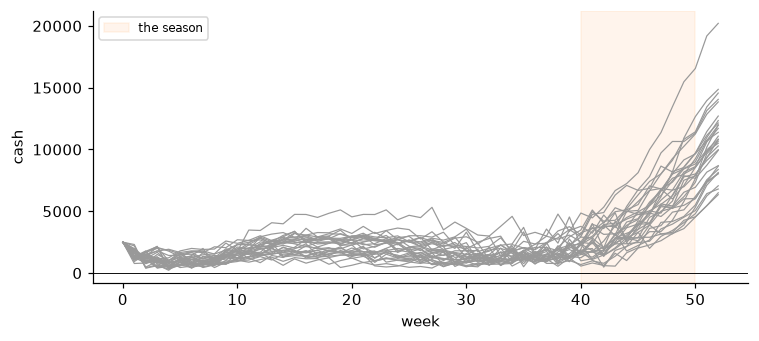

in use (cover 2, reserve 300)    insolvency  0.30%   profit    6621
no cash reserve                  insolvency  2.20%   profit    6542
more seasonal stock              insolvency  0.75%   profit    6700
much more seasonal stock         insolvency 12.35%   profit    6033
less seasonal stock              insolvency  0.20%   profit    6221


In [8]:
def assess(policy, n=2000, seed=11, st=stage):
    return evaluate(lambda: make_env(st), policy, n, spec=spec, stage=st, T=req.T, seed=seed)


rule = BaseStockRule(retailer, cover=2.0, reserve=300.0)
fig, ax = plt.subplots(figsize=(7, 3.2))
for s in range(30):
    shop = Shop(); obs, _ = shop.reset(seed=1000 + s); cash = [shop.cash]
    for week in range(52):
        obs, profit, _, end, info = shop.step(rule.deterministic(np.append(obs, 1.0)))
        cash.append(shop.cash)
        if shop.cash < 0 or end:
            break
    ax.plot(cash, color="C3" if min(cash) < 0 else "0.6", lw=0.8)
ax.axhline(0, color="k", lw=0.6)
ax.axvspan(retailer.peak - 6, retailer.season_end, color="C1", alpha=0.08, label="the season")
ax.set_xlabel("week"); ax.set_ylabel("cash"); ax.legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

rules = {"in use (cover 2, reserve 300)": BaseStockRule(retailer, 2.0, 300.0),
         "no cash reserve": BaseStockRule(retailer, 2.0, 0.0),
         "more seasonal stock": BaseStockRule(retailer, (2, 4, 4), 300.0),
         "much more seasonal stock": BaseStockRule(retailer, (2, 6, 5), 0.0),
         "less seasonal stock": BaseStockRule(retailer, (2, 1, 1), 300.0)}
rule_ev = {name: assess(r.deterministic) for name, r in rules.items()}
for name, e in rule_ev.items():
    print(f"{name:32s} insolvency {e.p_T:6.2%}   profit {e.U:7.0f}")

Cash falls through the first half of the year and rises with the season; a weak year deepens the trough. The cash
reserve lowers the risk and does not cost profit, because an insolvent year forfeits the rest of its profit. More
seasonal stock raises the risk faster than the profit.

## 5. Train PPO

The training function builds sixteen wrapped simulators, normalizes the reward scale, and records the insolvency rate
and the profit of every batch of training years with `BudgetMonitor`. Its options add what later sections need: a
prior fitted to a rule, a parameter anchor, and an adaptive multiplier.

**Theory.** The learner's discount `gamma` must be the problem's `beta`. Reward normalization rescales the objective
and leaves its optimum unchanged. An entropy bonus would be action regularization toward the uniform policy, which
biases the result; it is off (`ent_coef=0`).

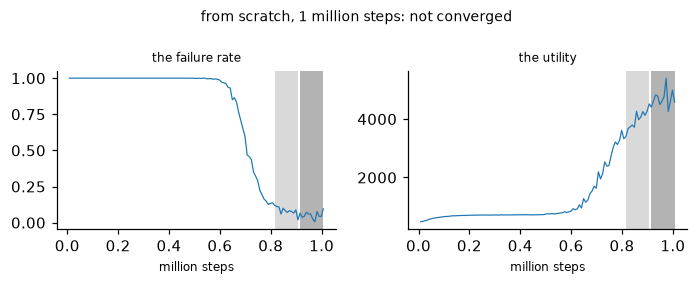

Training convergence over the last 12 batches, compared with the 12 before: not converged.
  the failure rate: still falling (0.08229 then 0.05241, a change of 36%)
  the utility: still rising (3984 then 4697, a change of 15%)
  the priced objective: still rising (3573 then 4435, a change of 19%)
  the action dispersion (log std): stable (-1.507 then -1.517)
Train longer before comparing this run with others or deploying its policy; a policy taken from a run that is still changing is the policy at the end of the run, and it should be validated as such.



after 1 million steps: insolvency 4.50%, profit 4696


In [9]:
PPO_SETTINGS = dict(n_steps=520, batch_size=1040, n_epochs=10, learning_rate=lambda p: 3e-4 * p, gamma=spec.beta,
                    gae_lambda=0.95, clip_range=0.2, ent_coef=0.0, device="cpu", verbose=0,
                    policy_kwargs=dict(net_arch=[64, 64], log_std_init=-1.0))


def train(stage, steps, seed=1, prior=None, anchor=None, dual=None):
    venv = DummyVecEnv([lambda: make_env(stage) for _ in range(16)])
    venv.seed(seed)
    venv = VecNormalize(venv, norm_obs=False, norm_reward=True, clip_reward=1e9, gamma=spec.beta)
    model = PPO("MlpPolicy", venv, seed=seed, **PPO_SETTINGS)
    if prior is not None:                                   # start from a network fitted to a rule (section 7)
        mean_action, log_std, states = prior
        fit_actor_mean(model, lambda o: np.stack([mean_action(x) for x in o]), states, seed=seed, steps=15000)
        set_log_std(model, log_std)
    if anchor:                                              # weight decay toward the starting weights (section 7)
        anchor = ParameterAnchor(model, anchor).install()
    monitor = BudgetMonitor(spec.beta, stage.m, horizon=spec.horizon, penalty=stage.penalty, dual=dual,
                            multiplier=None if dual else stage.multiplier)
    model.learn(steps, callback=([dual] if dual else []) + [monitor])   # dual: an adaptive multiplier (section 8)
    return model, monitor, anchor


model, monitor, _ = train(stage, 1_000_000)
monitor.plot(keys=("failure_rate", "U"), title="from scratch, 1 million steps"); plt.show()
print(monitor.convergence().explain())
short = assess(lambda o: model.predict(o)[0], n=1000, seed=13)
print(f"\nafter 1 million steps: insolvency {short.p_T:.2%}, profit {short.U:.0f}")

After a million steps (about 19,000 simulated years) the learner stays solvent in most years, and the convergence
check says the run has not converged: a short run gives the policy at the end of the run, not a trained one. The campaign ran the same function for 10 million steps. Its learning curves were still rising after
three and six million steps; compared at that point, the learners looked worse than the rule in use.

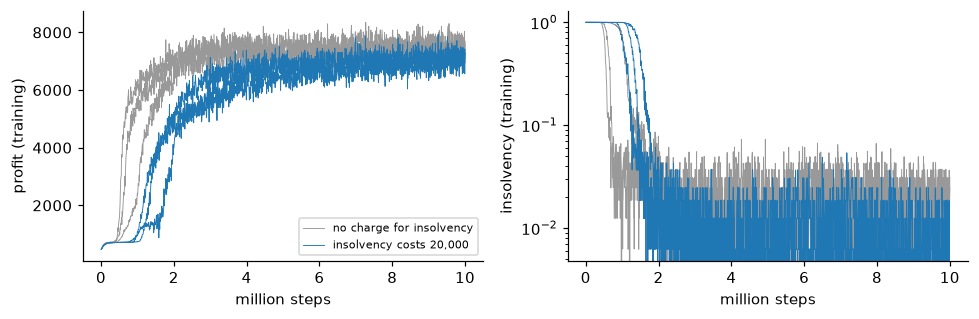

Convergence at the end of training (the toolbox's check on each run's record):
unpriced             converged in 2 of 3 seeds  (still changing: seed 1: failure rate)
lump-20000           converged in 1 of 3 seeds  (still changing: seed 1: failure rate; seed 3: failure rate)


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
for cfg, col in (("unpriced", "0.6"), ("lump-20000", "C0")):
    for r in camp.records(cfg):
        st = np.array([t["steps"] for t in r["monitor"]]) / 1e6
        ax[0].plot(st, [t["U"] for t in r["monitor"]], color=col, lw=0.6, label=r["note"] if r["seed"] == 1 else None)
        ax[1].plot(st, [t["failure_rate"] for t in r["monitor"]], color=col, lw=0.6)
ax[0].set_ylabel("profit (training)"); ax[1].set_ylabel("insolvency (training)"); ax[1].set_yscale("log")
for x in ax: x.set_xlabel("million steps")
ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()

print("Convergence at the end of training (the toolbox's check on each run's record):")
print(camp.convergence_table(["unpriced", "lump-20000"]))

Check the learning curves, and the convergence check, before comparing candidates. Even after 10 million steps, some
runs were still changing slowly at the end, mostly a failure rate still falling: their policies are the policies at
the end of the run, and a longer run might be safer.

## 6. The full campaign: costs of failure, and the deployed policy's dispersion

The campaign trained PPO from scratch with insolvency costing 0, 2,000, 5,000 and 20,000. The table shows the risk
and profit of the trained stochastic policies on 2,000 fresh years each: the mean over seeds and the range across
them. With 2,000 years, a risk of 1% is measured to within about half a percentage point.

configuration    seeds        failure (min-max)          utility (min-max)
unpriced             3     1.900% (1.60%-2.10%)           7486 (7242-7625)
lump-2000            3     1.483% (0.25%-2.20%)           7553 (7392-7708)
lump-5000            3     1.700% (1.15%-2.80%)           7512 (7313-7677)
lump-20000           3     0.617% (0.25%-0.85%)           7078 (6943-7232)


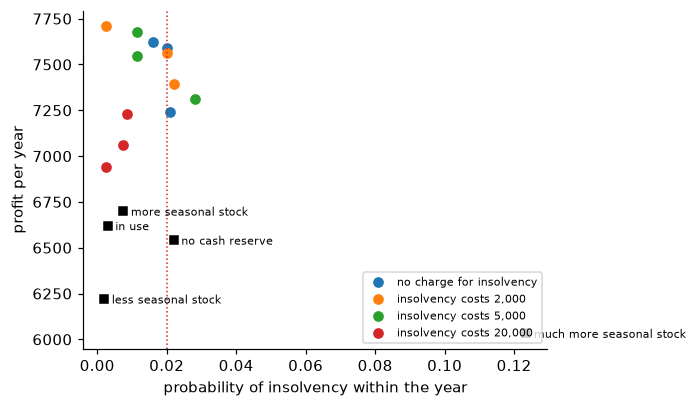

In [11]:
costs = ["unpriced", "lump-2000", "lump-5000", "lump-20000"]
print(Campaign.show(camp.table(costs)))

fig, ax = plt.subplots(figsize=(6.4, 3.8))
for i, cfg in enumerate(costs):
    for r in camp.records(cfg):
        ax.plot(np.mean(r["evaluation"]["failed"]), np.mean(r["evaluation"]["U"]), "o", color=f"C{i}",
                label=r["note"] if r["seed"] == 1 else None)
for name, e in rule_ev.items():
    ax.plot(e.p_T, e.U, "s", color="k", ms=5)
    ax.annotate(name.split(" (")[0], (e.p_T, e.U), textcoords="offset points", xytext=(5, -3), fontsize=7)
ax.axvline(req.alpha, color="C3", ls=":", lw=1)
ax.set_xlabel("probability of insolvency within the year"); ax.set_ylabel("profit per year")
ax.legend(fontsize=7, loc="lower right"); plt.tight_layout(); plt.show()

The learned policies earn more than the rule in use. Without a cost of insolvency they already avoid it in most
years, since an insolvent year forfeits the rest of its profit; costs of 2,000 and 5,000 change little, less than
the differences between seeds. A cost of 20,000, about three years of profit, moves the policies close to the rule's
level of risk, and they still earn more than the rule.

**Theory.** The price chooses a point on the trade-off between profit and risk: each trained policy is, up to the
learner's shortfall, the most profitable policy among those that go insolvent no more often than it does. A price
matters when it is large against what a failure already costs; here an insolvent year already forfeits its profit.

A stochastic policy draws its actions with noise, and the same network without the noise (its mean action) is a
different candidate. Here the noise is costly: random orders on lines that should not be ordered tie up cash.

In [12]:
noisy = assess(BaseStockRule(retailer, 2.0, 300.0, std=0.1, seed=1))
print(f"rule in use, exact orders:           insolvency {rule_ev['in use (cover 2, reserve 300)'].p_T:6.2%}  profit {rule_ev['in use (cover 2, reserve 300)'].U:7.0f}")
print(f"rule in use, orders with noise 0.1:  insolvency {noisy.p_T:6.2%}  profit {noisy.U:7.0f}")
print()
for cfg in ["lump-5000", "lump-20000"]:
    for s in camp.seeds(cfg):
        sto = camp.evaluation(cfg, s)
        mean = assess(camp.policy(cfg, s, deterministic=True), n=2000, seed=21)
        print(f"{cfg} seed {s}: stochastic policy {sto.p_T:6.2%} / {sto.U:6.0f}    mean action {mean.p_T:6.2%} / {mean.U:6.0f}")

rule in use, exact orders:           insolvency  0.30%  profit    6621
rule in use, orders with noise 0.1:  insolvency  8.55%  profit    6044



lump-5000 seed 1: stochastic policy  1.15% /   7677    mean action  1.00% /   7780


lump-5000 seed 2: stochastic policy  2.80% /   7313    mean action  2.45% /   7334


lump-5000 seed 3: stochastic policy  1.15% /   7547    mean action  1.40% /   7630


lump-20000 seed 1: stochastic policy  0.75% /   7060    mean action  0.85% /   7226


lump-20000 seed 2: stochastic policy  0.85% /   7232    mean action  0.40% /   7268


lump-20000 seed 3: stochastic policy  0.25% /   6943    mean action  0.50% /   7050


The rule loses much of its safety when its orders carry noise. The mean action of a learned policy earns more than
the stochastic policy it comes from in every case here, and is about as risky: sometimes safer, sometimes not, within
the measurement error. If you deploy the mean action, validate the mean action: it is the candidate you deploy.

## 7. Starting from the rule: a prior, and an anchor

A learner can start from the rule in use. Fit the network to the rule's orders, give it a small dispersion, and train
from there, freely or with a parameter anchor that pulls the weights back toward the fitted ones. The network at the
fitted weights is the **prior policy**: the policy one accepts if training gains nothing.

* The fit has to cover the states where the rule's safeguards act. Fitted on the states the rule itself visits, where
  cash is rarely low, the network misses the cash check. We fit on the states a noisy version of the rule visits.
* The prior policy is a candidate of its own: evaluate it before training.

**Theory.** A parameter anchor biases the learned policy toward the prior policy, and the learner inherits that
policy's risk and profit. It does not make the learner better than the prior.

In [13]:
def visited_states(policy, years=400, seed=12345):
    env, out = make_env(stage), []
    for i in range(years):
        obs, _ = env.reset(seed=seed + i)
        while True:
            out.append(obs)
            obs, _, terminated, truncated, _ = env.step(policy(obs))
            if terminated or truncated:
                break
    return np.asarray(out, dtype=np.float32)


states = visited_states(BaseStockRule(retailer, 2.0, 300.0, std=0.2, seed=3))      # a noisy rule visits low cash too
prior = (rule.mean_action, np.log(0.03), states)                                    # the rule's orders, dispersion 0.03
fitted = PPO("MlpPolicy", DummyVecEnv([lambda: make_env(stage) for _ in range(16)]), seed=1, **PPO_SETTINGS)
fit_actor_mean(fitted, lambda o: np.stack([rule.mean_action(x) for x in o]), states, seed=1, steps=15000)
set_log_std(fitted, np.log(0.03))
prior_ev = assess(lambda o: fitted.predict(o)[0], n=1000, seed=17)
print(f"the prior policy: insolvency {prior_ev.p_T:.2%}, profit {prior_ev.U:.0f}  (the rule: "
      f"{rule_ev['in use (cover 2, reserve 300)'].p_T:.2%}, {rule_ev['in use (cover 2, reserve 300)'].U:.0f})")

the prior policy: insolvency 1.70%, profit 6368  (the rule: 0.30%, 6621)


With `train(stage, steps, prior=prior)` the learner starts from this network, and `anchor=1.0` adds a parameter anchor
that pulls the weights back toward it. Here is one short run of each.

In [14]:
for name, options in {"from the prior, no anchor": dict(prior=prior), "from the prior, anchor 1": dict(prior=prior, anchor=1.0)}.items():
    m_, mon, anchor = train(stage, 1_000_000, **options)
    e = assess(lambda o: m_.predict(o)[0], n=1000, seed=19)
    moved = f"; weights moved {anchor.distance():.3f} from the prior" if anchor else ""
    print(f"{name:28s} insolvency {e.p_T:6.2%}, profit {e.U:6.0f}{moved}; training {mon.convergence().status}")

from the prior, no anchor    insolvency  1.30%, profit   6482; training converged


from the prior, anchor 1     insolvency  1.90%, profit   6404; weights moved 0.018 from the prior; training not converged


These short runs show how to start from a rule and anchor to it; they say little about what full training does. The
campaign ran both for 10 million steps:

In [15]:
starts = ["prior-only", "anchor-1", "anchor-10"]
print(Campaign.show(camp.table(["lump-5000"] + starts)))
for cfg in ["anchor-1", "anchor-10"]:
    print(f"{cfg}: weight distance from the prior at the end {np.round([r['anchor_distance'] for r in camp.records(cfg)], 3)}")
print("\nConvergence at the end of training:")
print(camp.convergence_table(["lump-5000"] + starts))

configuration    seeds        failure (min-max)          utility (min-max)
lump-5000            3     1.700% (1.15%-2.80%)           7512 (7313-7677)
prior-only           3     2.017% (1.00%-2.65%)           6592 (6418-6738)
anchor-1             3     1.000% (0.95%-1.10%)           6527 (6507-6566)
anchor-10            3     1.250% (1.10%-1.45%)           6460 (6398-6535)
anchor-1: weight distance from the prior at the end [0.016 0.013 0.014]
anchor-10: weight distance from the prior at the end [0.003 0.004 0.005]

Convergence at the end of training:


lump-5000            converged in 1 of 3 seeds  (still changing: seed 2: failure rate; seed 3: failure rate)
prior-only           converged in 3 of 3 seeds
anchor-1             converged in 2 of 3 seeds  (still changing: seed 2: failure rate)
anchor-10            converged in 1 of 3 seeds  (still changing: seed 2: failure rate; seed 3: failure rate)


The prior policy is close to the rule but riskier: the network smooths the rule's cash check. Trained from it, the
learner stays near it. The anchor holds it there, and its risk then varies less from seed to seed; without an anchor
the prior's small dispersion leaves little room to explore, and the learner moves only a little. Started from scratch,
the learner found clearly more profitable policies. Starting from a rule is a way to begin near behavior you accept,
not a way to improve on the rule; compare the rule, the learner from scratch and the learner from the rule.

## 8. A tolerance instead of a cost: the adaptive multiplier

Suppose the owners name no cost, and the lender asks for insolvency below 1%. An adaptive multiplier charges a
penalty at insolvency and moves it after every batch of training years, toward the level at which the insolvency
rate equals the tolerance: `train(Stage(m=0, penalty="multiplier", clip_utility=False), steps, dual=DualAscent(alpha,
step, multiplier0))`. The 20,000 run attains about 1%, so that is the level to expect.

Started from scratch with a step of half that level, the multiplier rose far past it: the untrained policy fails in
most years for many batches, and with a 1% tolerance the multiplier can come down only slowly, by at most 1% of its
step per batch. Started from the policy and the level of the 20,000 run, with a twentieth of that level as its step,
it only has to correct a small error. The control continues the 20,000 run for as long at that fixed cost.

an adaptive multiplier: 0.01 1000.0 20000.0


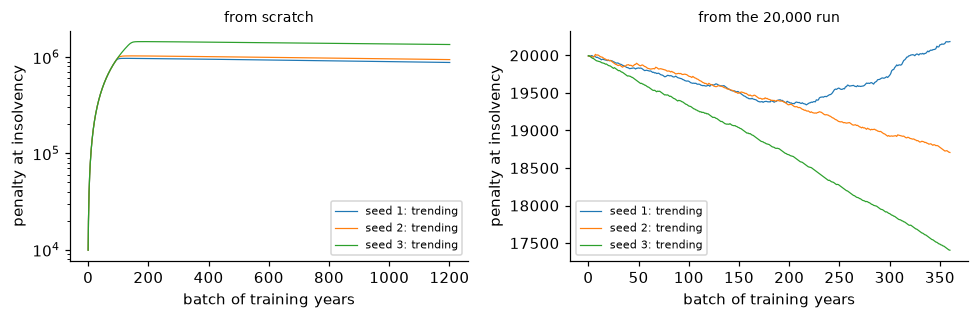

configuration    seeds        failure (min-max)          utility (min-max)
adaptive-1pct        3     0.067% (0.00%-0.10%)           3843 (1370-5940)
adaptive-1pct-warm     3     0.650% (0.10%-1.35%)           7188 (7124-7298)
lump-20000-long      3     0.517% (0.05%-0.80%)           7241 (7185-7336)


In [16]:
dual = DualAscent(alpha=0.01, step=1000.0, multiplier0=20000.0)          # as the warm start of the campaign
print("an adaptive multiplier:", dual.alpha, dual.step, dual.multiplier)
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
for i, cfg in enumerate(["adaptive-1pct", "adaptive-1pct-warm"]):
    for r in camp.records(cfg):
        ax[i].plot([t["multiplier"] for t in r["dual"]["trace"]], lw=0.8, label=f"seed {r['seed']}: {r['dual']['diagnosis']['status']}")
    ax[i].set_title("from scratch" if i == 0 else "from the 20,000 run", fontsize=9)
    ax[i].set_xlabel("batch of training years"); ax[i].set_ylabel("penalty at insolvency"); ax[i].legend(fontsize=7)
ax[0].set_yscale("log")
plt.tight_layout(); plt.show()
print(Campaign.show(camp.table(["adaptive-1pct", "adaptive-1pct-warm", "lump-20000-long"])))

From scratch, the multiplier ended near a million and the policies became overly cautious: they almost never go
insolvent and give up much of their profit. Started warm, the multiplier stayed near its level and the policies
match those of the control. For a tolerance, train at a few fixed costs or prices first and pick the one whose runs
meet it; a multiplier, if used, should start from there. `DualAscent.diagnose` reports whether it converged.

## 9. Validate the candidates and report

The candidates inspected are the rule in use, its variants, and the learned policies. We validate the rule in use and
the most profitable learned candidate that met the tolerance on its first evaluation, each on 5,000 fresh years,
with the error shared among the eight candidates.

**Theory.** The exact binomial test holds for any fixed policy, however it was found; picking the best-looking
candidate does not inflate its error when the error is shared among all the candidates inspected.

In [17]:
learned = [(cfg, s) for cfg in costs + starts for s in camp.seeds(cfg)]
best = max(learned, key=lambda cs: camp.evaluation(*cs).U if camp.evaluation(*cs).p_T < req.alpha else -np.inf)
print("most profitable learned candidate under the tolerance:", best)
final = {"the rule in use": assess(rules["in use (cover 2, reserve 300)"].deterministic, n=5000, seed=31),
         f"the learned policy {best[0]}, seed {best[1]}": assess(camp.policy(*best), n=5000, seed=31)}
for name, e in final.items():
    print()
    training = camp.convergence(*best) if name.startswith("the learned") else None
    print(interpret(spec, req, stage, e, candidate_name=name, training=training).summary(resource="cash", period="weeks"))

most profitable learned candidate under the tolerance: ('lump-2000', 1)


The rule in use was run on 5000 fresh episodes. It ran out of cash within 52 weeks in 12 of them (0.24%).
With confidence 0.95, its probability of running out within 52 weeks is at most 0.474% (the error 0.05 is shared among 8 candidates).
Requirement (at most 2.00%): met.
Utility per episode: 6602 (standard error 46).
Episodes that came within 5% of running out, or ran out: 0.4%.

What this test does not show:
  - that the policy is the best possible at this risk: how far training fell short of the optimum is not measured;
  - its risk over more than 52 weeks, or that of other policies (its mean action, a retrained network);
  - its behavior outside the simulator.
Every bound with its assumptions: report.text().

The learned policy lump-2000, seed 1 was run on 5000 fresh episodes. It ran out of cash within 52 weeks in 19 of them (0.38%).
With confidence 0.95, its probability of running out within 52 weeks is at most 0.657% (the error 0.05 is shared among 8 candidates).
Requirement (at

Both pass the lender's tolerance; the report states what the test shows and what it does not. Which to deploy is the
firm's choice between profit and risk, and the evidence for either is the same kind. `report.text()` lists every
bound with its assumptions.

## Your own simulator

To apply the method to a problem of your own, change these cells:

1. `Shop`: your simulator, with `reset`, `step`, an observation space and an action space; put the resource it
   consumes in `info`;
2. `cash_outflow`: the resource one step consumes, wrapped in `RunningMaxCost` if it can also be replenished;
3. `spec`, `req`, `stage`: the budget, the horizon, bounds on the reward, the requirement, and the price or the cost
   of failure;
4. `make_env`: the wrapper (add `observe_time=True` if the horizon is fixed and your observation has no clock);
5. `PPO_SETTINGS` and `train`: your learner, with `gamma = spec.beta`.

Then check the wrapped simulator, evaluate any rule you already use, plan, train at a few prices or costs while
watching the learning curves, and validate the policy you deploy. `python campaigns/run.py retailer lump-5000 --seed 4`
reruns one configuration of the campaign.